In [130]:

from deap import base, creator, gp
import matplotlib.pyplot as pyplot
import numpy as np
import pickle
import random
import operator
import multiprocessing as mp
from deap import tools
import scipy
from Dataloader.dataloader import load_nslkdd as load_data

creator.create("FitnessMin", base.Fitness, weights=(-1.0,))
creator.create("Individual", list, fitness=creator.FitnessMin)

CXPB, MUTPB, NGEN = 0.8, 0.04, 50
TOURNSIZE = 3
IND_SIZE = 41

POPCOUNT = 100




/Users/armindelmo/Library/Python/3.9/lib/python/site-packages/deap/creator.py:185: RuntimeWarning: A class named 'FitnessMin' has already been created and it will be overwritten. Consider deleting previous creation of that class or rename it.
  warnings.warn("A class named '{0}' has already been created and it "
/Users/armindelmo/Library/Python/3.9/lib/python/site-packages/deap/creator.py:185: RuntimeWarning: A class named 'Individual' has already been created and it will be overwritten. Consider deleting previous creation of that class or rename it.
  warnings.warn("A class named '{0}' has already been created and it "


In [131]:
# Simulated Annealing Parameters
TEMP = 1.0 # gets a 10% deduction every generation via cooling rate
COOLING_RATE = 0.9 # applied once a generation
ITER_PER_OFFSPRING = 3

# Dataloader
We'll need to wait on Benny to finish up his dataloader to do this

In [119]:
data = load_data(binary_labels=True, scale=True)

# Define Individuals

We are using complex sets to collect the decisions of the individuals

In [120]:
# Genetic Operators

def pdiv(a, b):
    return np.where(np.abs(b) > 1e-12, a / b, 1.0)

def gt(a, b):
    return (a > b).astype(float)

def lt(a, b):
    return 1.0 if a < b else 0.0

def b_and(a, b):
    return 1.0 if (a > 0.5 and b > 0.5) else 0.0

def b_or(a, b):
    return 1.0 if (a > 0.5 or b > 0.5) else 0.0

def b_not(a):
    return 0.0 if a > 0.5 else 1.0

def ifte(cond, x, y):
    return x if cond > 0.5 else y



In [121]:
from Dataloader.dataloader import FEATURE_NAMES

pset = gp.PrimitiveSet("MAIN", 41)

for i, name in enumerate(FEATURE_NAMES[:41]):
    pset.renameArguments(**{f"ARG{i}": name})

pset.addPrimitive(operator.add, 2)
pset.addPrimitive(operator.sub, 2)
pset.addPrimitive(operator.mul, 2)

pset.addPrimitive(pdiv, 2)
pset.addPrimitive(gt, 2)
pset.addPrimitive(lt, 2)
pset.addPrimitive(b_and, 2)
pset.addPrimitive(b_or, 2)
pset.addPrimitive(b_not, 1)
pset.addPrimitive(ifte, 3)

if not hasattr(creator, "FitnessMax"):
    creator.create("FitnessMax", base.Fitness, weights=(1.0,))
if not hasattr(creator, "GPIndividual"):
    creator.create("GPIndividual", gp.PrimitiveTree, fitness=creator.FitnessMax)


In [122]:
toolbox = base.Toolbox()
toolbox.register("expr", gp.genHalfAndHalf, pset=pset, min_=1, max_=3)
toolbox.register("individual", tools.initIterate, creator.GPIndividual, toolbox.expr)
toolbox.register("population", tools.initRepeat, list, toolbox.individual)

# genetic operators
toolbox.register("compile", gp.compile, pset=pset)
toolbox.register("mate", gp.cxOnePoint)
toolbox.register("expr_mut", gp.genFull, min_=0, max_=2)
toolbox.register("mutate", gp.mutUniform, expr=toolbox.expr_mut, pset=pset)
toolbox.register("select", tools.selTournament, tournsize=3)

# bloat control
toolbox.decorate("mate", gp.staticLimit(key=operator.attrgetter("height"), max_value=8))
toolbox.decorate("mutate", gp.staticLimit(key=operator.attrgetter("height"), max_value=8))
toolbox.decorate("mate", gp.staticLimit(key=len, max_value=80))
toolbox.decorate("mutate", gp.staticLimit(key=len, max_value=80))

# Evaluation Formulas
Calculate the haversine distance of the whole path they took.

In [138]:
X_train = data["X_train"].to_numpy(dtype=float)
y_train = data["y_train"].to_numpy(dtype=int)
X_val = data["X_val"].to_numpy(dtype=float) if len(data["X_val"]) else None
y_val = data["y_val"].to_numpy(dtype=int) if len(data["y_val"]) else None
X_test = data["X_test"].to_numpy(dtype=float)
y_test = data["y_test"].to_numpy(dtype=int)

# only use the training set, as we will measure accuracy via testing set in the end
def training_accuracy(individual):
    func = toolbox.compile(expr=individual)
    correct = 0
    try:
        preds = func(*X_train.T)
        predictions = (np.array(preds) > 0.5).astype(int)
        correct = (predictions == y_train).sum()
    except:
        return 0.0
    return correct / len(y_train)

    return correct / len(y_train)
def testing_accuracy(individual):
    func = toolbox.compile(expr=individual)
    correct = 0
    try:
        preds = func(*X_test.T)
        predictions = (np.array(preds) > 0.5).astype(int)
        correct = (predictions == y_test).sum()
    except:
        return 0.0
    return correct / len(y_test)

# count how many arguments we use
def count_features(individual):
    used = set()
    for node in individual:
        if isinstance(node, gp.Terminal) and isinstance(node, str) and node.name in FEATURE_NAMES[:41]:
            used.add(node.name)
    return len(used)

def fitness_evaluation(individual):
    features_selected = count_features(individual)
    return ((0.8 * training_accuracy(individual) + 0.2 * (1 - features_selected / 41)),)

In [ ]:
def get_neighbor(individual):
    neighbor = toolbox.clone(individual)
    neighbor, = toolbox.mutate(neighbor)
    
    if neighbor.fitness.valid:
        del neighbor.fitness.values
    return neighbor

def simulate_annealing(individual, temp):

    current = toolbox.clone(individual)
    if not current.fitness.valid:
        current.fitness.values = toolbox.evaluate(current)

    current_score = current.fitness.values[0]
    best = toolbox.clone(current)
    best_score = current_score

    for _ in range(ITER_PER_OFFSPRING):
        candidate = get_neighbor(current)
        candidate_score = toolbox.evaluate(candidate)[0]

        diff = candidate_score - current_score  # maximize
        prob = np.exp(-(diff / temp))
        accept = diff > 0 or random.random() < prob

        if accept:
            current = candidate
            current_score = candidate_score
            if current_score > best_score:
                best = toolbox.clone(current)
                best_score = current_score

    best.fitness.values = (best_score,)
    return best

toolbox.register("simulate_annealing", simulate_annealing)

In [125]:
# following is meant to store the data of our runs
stats = tools.Statistics(lambda ind: ind.fitness.values[0])
stats.register("avg", np.mean, axis=0)
stats.register("std", np.std, axis=0)
stats.register("min", np.min, axis=0)
stats.register("max", np.max, axis=0)


# Simulation Function
The genetic loop is made here so we can run with multiple different problems later in the code.
We are going to change the mutation, mating, and other variables for each problem representation

In [159]:
def run_sim(_):
    
    temp = TEMP
    hof = tools.HallOfFame(1)
    pop = toolbox.population(n=POPCOUNT)

    # initial evaluation
    invalid = [ind for ind in pop if not ind.fitness.valid]
    fitnesses = map(toolbox.evaluate, invalid)
    for ind, fit in zip(invalid, fitnesses):
        ind.fitness.values = fit

    logbook = tools.Logbook()
    for g in range(NGEN):
        # always ensure validity before stats
        invalid = [ind for ind in pop if not ind.fitness.valid]
        fitnesses = map(toolbox.evaluate, invalid)
        for ind, fit in zip(invalid, fitnesses):
            ind.fitness.values = fit

        record = stats.compile(pop)
        best_ind = tools.selBest(pop, 1)[0]
        logbook.record(gen=g, best_ind=best_ind[:], **record)

        offspring = list(map(toolbox.clone, toolbox.select(pop, len(pop))))

        for child1, child2 in zip(offspring[::2], offspring[1::2]):
            if random.random() < CXPB:
                toolbox.mate(child1, child2)
                del child1.fitness.values
                del child2.fitness.values

        for mutant in offspring:
            if random.random() < MUTPB:
                toolbox.mutate(mutant)
                del mutant.fitness.values

        invalid = [ind for ind in offspring if not ind.fitness.valid]
        fitnesses = map(toolbox.evaluate, invalid)
        for ind, fit in zip(invalid, fitnesses):
            ind.fitness.values = fit
            
        #k = 10
        #elites = tools.selBest(pop, k)
        #improved_elites = [toolbox.simulate_annealing(elitist, temp) for elitist in elites]

        #worst_idx = sorted(
        #    range(len(offspring)),
        #    key=lambda i: offspring[i].fitness.values[0]
        #)[:k]
        #for idx, elite in zip(worst_idx, improved_elites):
        #    offspring[idx] = elite
        pop[:] = offspring
        hof.update(pop)
        
        temp *= COOLING_RATE

    return logbook, hof

# Recording all the Information
The following codeblock holds the function we will use to compile all 50 runs for each problem representation.
We collect the best individual out of each iteration, and use it for a graph shown in the paper.

In [143]:
def combine_logbooks(all_logbooks):
    n_runs = len(all_logbooks)
    max_gen = NGEN
    
    combined_books = {
        "gen": np.arange(max_gen),
        "avg_mean": [],
        "avg_ci": [],
        "best_mean": [],
        "best_ci": [],
    }
    
    for gen_index in range(max_gen):
        avg_fitness = []
        best_fitness = []

        for lb in all_logbooks:
            record = lb[gen_index]
            avg_fitness.append(record["avg"])
            best_fitness.append(record["min"])

        # turn into arrays
        avg_fitness = np.array(avg_fitness)
        best_fitness = np.array(best_fitness)

        # means
        combined_books["avg_mean"].append(np.mean(avg_fitness))
        combined_books["best_mean"].append(np.mean(best_fitness))

        # ci's
        combined_books["avg_ci"].append(1.96 * np.std(avg_fitness, ddof=1) / np.sqrt(n_runs))
        combined_books["best_ci"].append(1.96 * np.std(best_fitness, ddof=1) / np.sqrt(n_runs))
        
    return combined_books

    

# Approaches
The following approaches will be done in each coding block


## Permutation

We are shuffling around the order of the cities to get the best possible combination.

In [160]:
mp.set_start_method("fork", force=True)

_ = None
toolbox.register("evaluate", fitness_evaluation)

results = None
with mp.Pool() as pool:
   results = pool.map(run_sim, range(50))
    
# exporting all the information to use for graphing
logbooks, hofs = zip(*results)


logbook_compiled = combine_logbooks(logbooks)
# put in where your logbooks saved
with open("/Users/armindelmo/Documents/College/Spr26/UCF-CAP5512-Evolutionary-Computation/Paper/EvolutionaryComputationPaper/hw3.ipynbcompiled_logbooks_simple.pkl", 'wb') as file:
    pickle.dump(logbook_compiled, file)
        
with open("/Users/armindelmo/Documents/College/Spr26/UCF-CAP5512-Evolutionary-Computation/Paper/EvolutionaryComputationPaper/hof_simple.pkl", 'wb') as file:
    pickle.dump(hofs, file)
#*/

/var/folders/5b/c6r2gv811hz31j3kl7jwbv300000gn/T/ipykernel_57912/1482819356.py:4: RuntimeWarning: divide by zero encountered in divide
  return np.where(np.abs(b) > 1e-12, a / b, 1.0)
/var/folders/5b/c6r2gv811hz31j3kl7jwbv300000gn/T/ipykernel_57912/1482819356.py:4: RuntimeWarning: divide by zero encountered in divide
  return np.where(np.abs(b) > 1e-12, a / b, 1.0)
/var/folders/5b/c6r2gv811hz31j3kl7jwbv300000gn/T/ipykernel_57912/1482819356.py:4: RuntimeWarning: divide by zero encountered in divide
  return np.where(np.abs(b) > 1e-12, a / b, 1.0)
/var/folders/5b/c6r2gv811hz31j3kl7jwbv300000gn/T/ipykernel_57912/1482819356.py:4: RuntimeWarning: invalid value encountered in divide
  return np.where(np.abs(b) > 1e-12, a / b, 1.0)
/var/folders/5b/c6r2gv811hz31j3kl7jwbv300000gn/T/ipykernel_57912/1482819356.py:4: RuntimeWarning: invalid value encountered in divide
  return np.where(np.abs(b) > 1e-12, a / b, 1.0)
/var/folders/5b/c6r2gv811hz31j3kl7jwbv300000gn/T/ipykernel_57912/1482819356.py:4: 

# Plot Graphs
Running the code to build the graphs for the assignment.

In [ ]:
def plot_graph(title, x_label, y_label, datafile_path, save_graph):
    gen = range(1, NGEN + 1)
    
    data = None
    with open(datafile_path, 'rb') as file:
        data = pickle.load(file)
        
    avg = np.array(data["avg_mean"]) * 100
    ci = np.array(data["avg_ci"]) * 100
    
    pyplot.figure()
    
    pyplot.plot(gen, avg, label="representation", color="blue")
    pyplot.fill_between(gen, avg - ci, avg + ci, alpha = 0.2, label="95% ci", color="red")
        
    # beautifying the graph
    pyplot.title(title)
    pyplot.xlabel(x_label)
    pyplot.ylabel(y_label)
    pyplot.locator_params(axis='y', nbins=20)
    # display legend
    pyplot.legend()
    
    if save_graph:
        pyplot.savefig(f"{title}.png", dpi = 500)
        pyplot.close()
    else:   
        pyplot.show()
adj_path = "/Users/armindelmo/Documents/College/Spr26/UCF-CAP5512-Evolutionary-Computation/Paper/EvolutionaryComputationPaper/compiled_logbooks_simple.pkl"
perm_path = "/Users/armindelmo/Documents/College/Spr26/UCF-CAP5512-Evolutionary-Computation/Paper/EvolutionaryComputationPaper/compiled_logbooks_hybrid.pkl"
#andkeys_path = "/Users/armindelmo/Documents/UCF-CAP5512-Evolutionary-Computation/HW3/compiled_logbooks_randkeys.pkl"

def plot_all_graphs(names, paths):
    for i in range(len(names)):
        plot_graph(f"{names[i]} n = 200", "generation", "% accuracy", paths[i], True)
plot_all_graphs(["simple", "hybrid"], [adj_path, perm_path])
#plot_graph(f"Simple, n = 200",
 #          "generation", 
  #         "\% accuracy", 
   #        perm_path,
    #       True
#)

SyntaxError: EOL while scanning string literal (1794787432.py, line 35)

In [162]:
# the following plots all of the graphs against each other.
def plot_multigraph(title, x_label, y_label, datafile_paths, names, save_graph):
       
    pyplot.figure()
    
    # iterate through all of the pickles
    for path in datafile_paths:
        gen = range(1, NGEN + 1)
    
        data = None
        with open(path, 'rb') as file:
            data = pickle.load(file)
        
        avg = np.array(data["avg_mean"]) * 100
        ci = np.array(data["avg_ci"]) * 100
        
        pyplot.plot(gen, avg, label=names[datafile_paths.index(path)])
        pyplot.fill_between(gen, avg - ci, avg + ci, alpha = 0.2, label="95% ci")
        
    # beautifying the graph
    pyplot.title(title)
    pyplot.xlabel(x_label)
    pyplot.ylabel(y_label)
    
    # display legend
    pyplot.legend()
    
    if save_graph:
        pyplot.savefig(f"{title}.png", dpi = 300)
        pyplot.close()
    else:   
        pyplot.show()

all_paths = [adj_path, perm_path]
names = ["Simple", "Hybrid"]
plot_multigraph("All Problem Representations, n = 200, 50 runs averages", "generation", "% accuracy", all_paths, names, True)


# Travel Chart
The following are charts of the paths that these hall of famers took, this is especially important as we can see what paths they all universally chose across all 50 runs.

(<deap.tools.support.HallOfFame object at 0x112afd4c0>, <deap.tools.support.HallOfFame object at 0x112afdee0>, <deap.tools.support.HallOfFame object at 0x113655dc0>, <deap.tools.support.HallOfFame object at 0x11419a8b0>, <deap.tools.support.HallOfFame object at 0x112077280>, <deap.tools.support.HallOfFame object at 0x113892fd0>, <deap.tools.support.HallOfFame object at 0x113439250>, <deap.tools.support.HallOfFame object at 0x1134397f0>, <deap.tools.support.HallOfFame object at 0x113439a30>, <deap.tools.support.HallOfFame object at 0x1134392e0>, <deap.tools.support.HallOfFame object at 0x113439700>, <deap.tools.support.HallOfFame object at 0x113439c70>, <deap.tools.support.HallOfFame object at 0x113eddcd0>, <deap.tools.support.HallOfFame object at 0x1121ffe50>, <deap.tools.support.HallOfFame object at 0x1121ff6a0>, <deap.tools.support.HallOfFame object at 0x1121ffca0>, <deap.tools.support.HallOfFame object at 0x1121ffb50>, <deap.tools.support.HallOfFame object at 0x1121ff610>, <deap.too

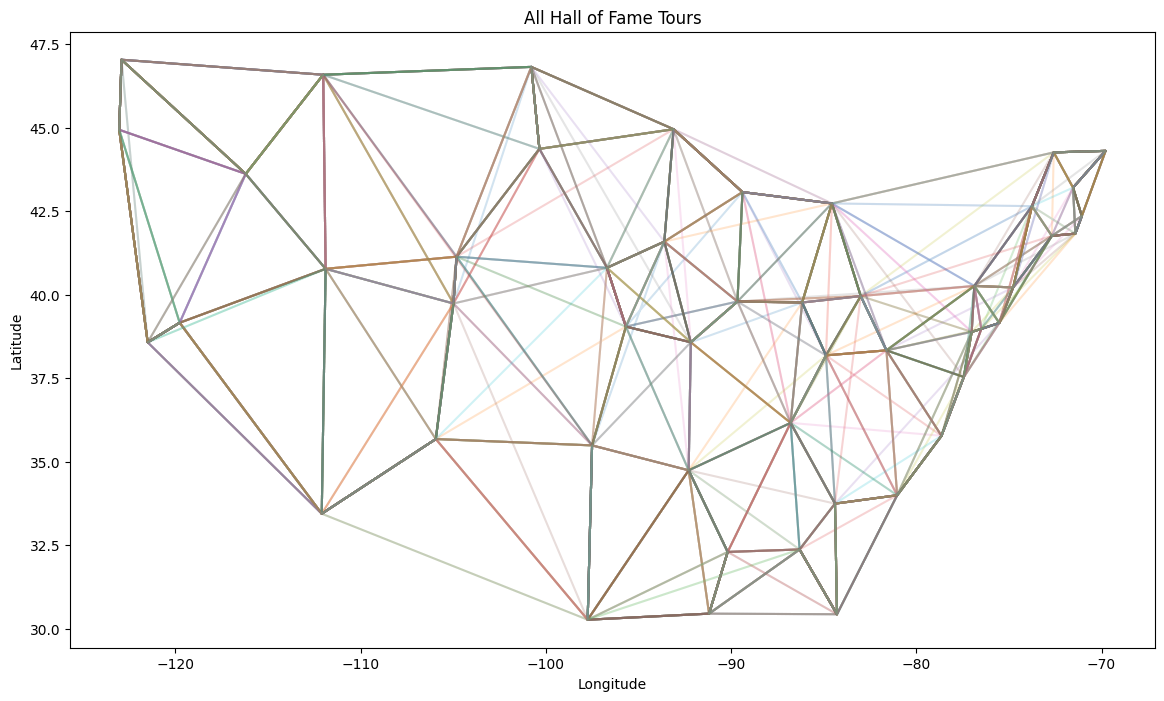

In [ ]:
def travel_chart_all(hofs):
    fig, ax = pyplot.subplots(figsize=(14, 8))

    for hof in hofs:
        for ind in hof:
            tour = list(ind) + [ind[0]]
            lons = [CITY_DATA[c][1] for c in tour]
            lats = [CITY_DATA[c][0] for c in tour]

            ax.plot(lons, lats, alpha=0.2)

    ax.set_title("All Hall of Fame Tours")
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    pyplot.show()
    
with open("/Users/armindelmo/Documents/UCF-CAP5512-Evolutionary-Computation/HW3/hof_permutation.pkl", 'rb') as file:
    data = pickle.load(file)
    print(data)
fitness_values = [hof[0].fitness.values[0] for hof in data]
travel_chart_all(data)